# Online Retail II: EDA 

### 0. Setup
---

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

---
## problem definition & data sourcing
### 1.1 Business problem 
The business is an online shop that sells gifts and homeware mostly to wholesale their customers we want to understand what customers buy how much and when
### Dataset provenance:
- Source: UCI Machine Learning Repository "Online retail II" 
- What it is: real transactions from a UK online retailer. 
- Period: December 2009 to December 2011. 
- Row: = one product line inside one invoice.

In [12]:
PATH = "online_retail_II.csv"

df= pd.read_csv(PATH)
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


- ### Schema audit

In [13]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [14]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df.dtypes

Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

- ### Feature Cardinality
How many unique values a column has.


In [15]:
card = df.nunique().to_frame("unique_values")
card["pct_of_rows"] = card["unique_values"] / len(df) * 100
card

,unique_values,pct_of_rows
Invoice,53628,5.02
StockCode,5305,0.50
Description,5698,0.53
Quantity,1057,0.10
InvoiceDate,47635,4.46
Price,2807,0.26
Customer ID,5942,0.56
Country,43,0.00


- ### Null-distribution map
- A table of Missing values
- A map: each row is a record and each column is a feature
- A coloured cell means"missing" so we can see wheter gaps cluster.

In [16]:
nulls = df.isna().sum().to_frame("missing")
nulls["pct"] = nulls["missing"] / len(df) * 100
nulls

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


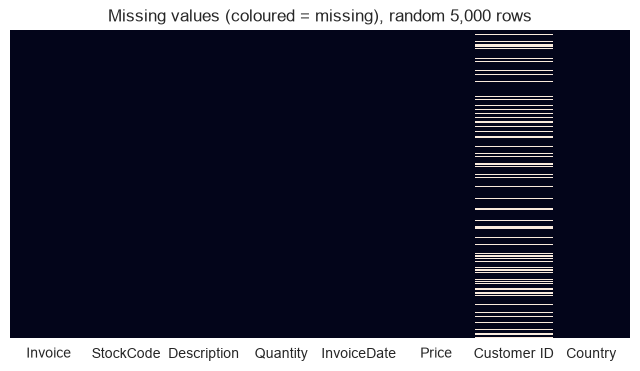

In [17]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.sample(5000, random_state=42).isna(), cbar=False, yticklabels=False)
plt.title("Missing values (coloured = missing), random 5,000 rows")
plt.show()

- ### Duplicates 
 

In [19]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Share of all rows:", f"{df.duplicated().mean():.2%}")

Exact duplicate rows: 34335
Share of all rows: 3.22%


---
## Exploratory Data Analysis
### Central tendency, spread, skewness, kurtosis 
- Mean/Median show how the typical value. if the mean is far above the md,  big values are pulling it up.
- Std shows how spread the values are.
- skewness shows which way the distribution leans. above 0 means a long tail to the right.
- Kurtosis shows how heavy the tails are. above zero means more extreme values than a bell curve.

In [20]:
cols = ["Quantity", "Price"]

summary = df[cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
summary["skewness"] = df[cols].skew()
summary["kurtosis"] = df[cols].kurt()
summary

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
Quantity,"1,067,371.00",9.94,172.71,"-80,995.00",-3.00,1.00,1.00,3.00,10.00,30.00,100.00,"80,995.00",4.00,"155,059.69"
Price,"1,067,371.00",4.65,123.55,"-53,594.36",0.21,0.42,1.25,2.10,4.15,9.95,18.00,"38,970.00",-69.16,"73,751.83"


- ### Distributions
- Money and quantity data is usually heavily right-skewed. 
- On the raw scale the histogram looks like one tall bar next to the axis, with the rest squashed flat. 
- A log scale stretches small values and shrinks big ones so the shape is visible. 
- We take the log only for the chart. We use only values above zero, because log can’t handle zero or negatives.

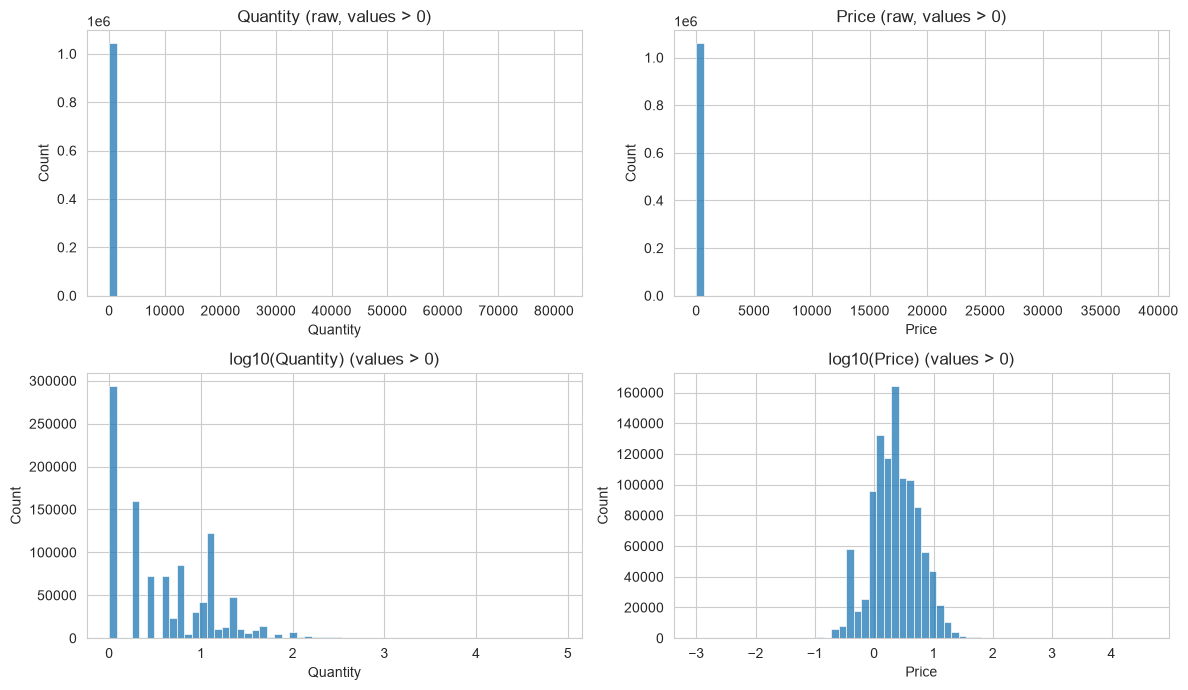

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))

for i, c in enumerate(cols):
    positive = df.loc[df[c] > 0, c]               # temporary, for the chart only
    sns.histplot(positive, bins=60, ax=ax[0, i])
    ax[0, i].set_title(f"{c} (raw, values > 0)")
    sns.histplot(np.log10(positive), bins=60, ax=ax[1, i])
    ax[1, i].set_title(f"log10({c}) (values > 0)")

plt.tight_layout(); plt.show()

In [23]:
for c in cols:
    print(c, "-> zero or negative values:", (df[c] <= 0).sum())

Quantity -> zero or negative values: 22950
Price -> zero or negative values: 6207


### Categorical columns
- How often each value appears

In [24]:
df["Country"].value_counts().head(10)

Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64

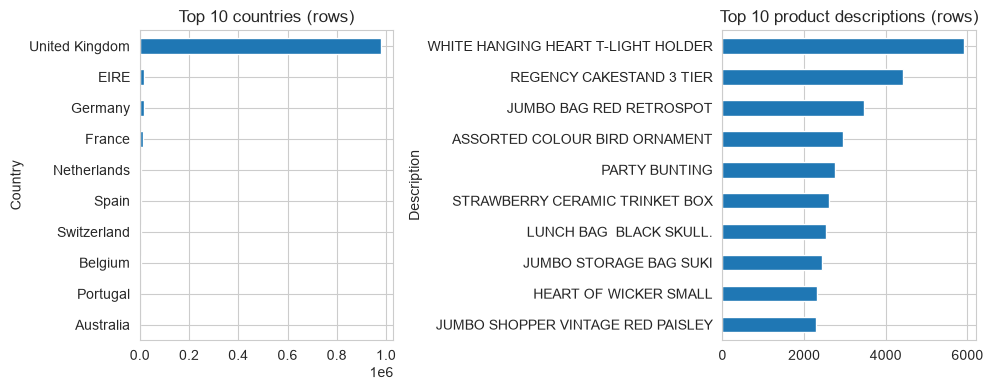

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["Country"].value_counts().head(10).plot.barh(ax=ax[0]).invert_yaxis()
ax[0].set_title("Top 10 countries (rows)")
df["Description"].value_counts().head(10).plot.barh(ax=ax[1]).invert_yaxis()
ax[1].set_title("Top 10 product descriptions (rows)")
plt.tight_layout(); plt.show()

- Real product code start with five digits Here we only at codes don't don't follow the pattern.

In [31]:
code = df["StockCode"].astype(str)
odd = code[~code.str.match(r"^\d{5}")]
print("Rows with non-standard StockCode:", len(odd))
odd.value_counts().head(15)

Rows with non-standard StockCode: 6093


StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
Name: count, dtype: int64

### Time patterns
- Counting how many different invoices happen per month, weekday, and hour.

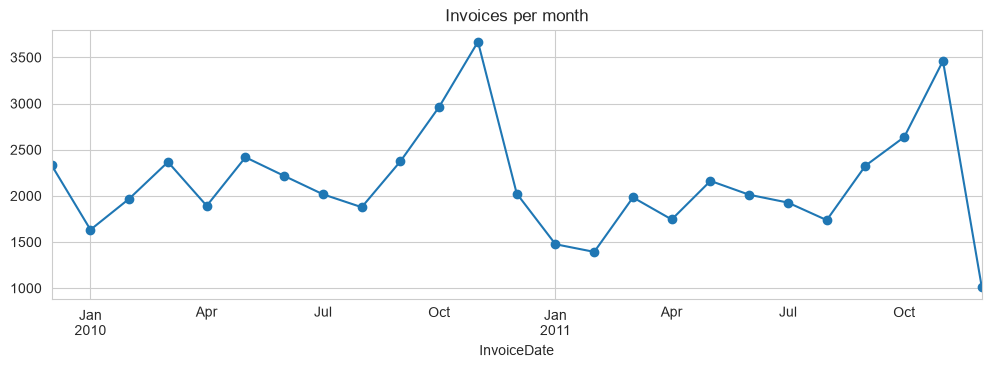

In [36]:
dates = pd.to_datetime(df["InvoiceDate"])

monthly = df.groupby(dates.dt.to_period("M"))["Invoice"].nunique()
monthly.plot(figsize=(12, 3.5), marker="o", title="Invoices per month")

plt.show()

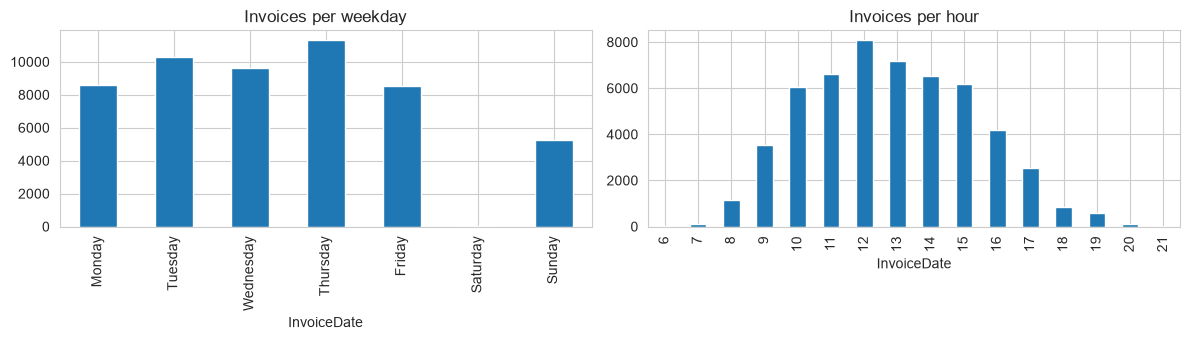

In [37]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.groupby(dates.dt.day_name())["Invoice"].nunique().reindex(order).plot.bar(ax=ax[0], title="Invoices per weekday")
df.groupby(dates.dt.hour)["Invoice"].nunique().plot.bar(ax=ax[1], title="Invoices per hour")
plt.tight_layout(); plt.show()

### Correlation (Pearson and Spearman)
- Correlation runs from -1 to +1 and shows whether two columns move together. 
- Pearson measures straight-line relationships and is sensitive to outliers.
- Spearman compares ranks, so copes better with skewed data


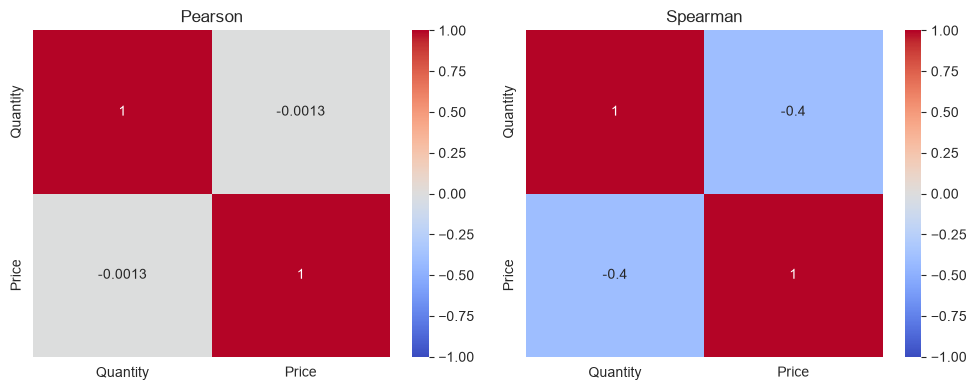

In [38]:
num = df[["Quantity", "Price"]]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(num.corr(method="pearson"),  annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title("Pearson")
sns.heatmap(num.corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title("Spearman")
plt.tight_layout(); plt.show()

- ### Collinearity (VIF)
Collinearity means two features carry almost the same information. VIF measures it. 
- Rough guide: under 5 is fine, 5–10 is worth watching, and above 10 is a problem for linear models. 
- With only two numeric columns this check is very limited, but it’s still worth running.

In [39]:
X = df[["Quantity", "Price"]].dropna()
Xc = sm.add_constant(X)

vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]
})
vif

,feature,VIF
0,Quantity,1.00
1,Price,1.00
